# **INTELIGENCIA ARTIFICIAL — UNIDAD 3**
## **Práctica 1: Red neuronal totalmente conectada para reconocer señas ASL**

*Notebook desarrollado a partir del ejemplo original de la práctica; se compararon dos versiones de referencia para elegir y justificar la arquitectura.*



## Deep Learning
## Fully Connected Deep Neural Networks

- Objective

The aim of this part of the activity is to apply your understanding of Fully Connected Networks by implementing a multilayer network for the [Kaggle ASL (American Sign Language) dataset](https://www.kaggle.com/datasets/grassknoted/asl-alphabet). While you have been provided with a complete solution for a Fully Connected Network using Numpy for the MNIST dataset, you are encouraged to try to come up with the solution.

- Instructions


    Load and Preprocess Data: You are provided a starter code to load the data. Be sure to understand the code.

    Review MNIST Notebook (Optional): Before diving into this activity, you have the option to revisit the MNIST example to refresh your understanding of how to build a Fully Connected Network using Numpy.

    Start Fresh: Although you can refer to the MNIST solution at any point, try to implement the network for the ASL dataset on your own. This will reinforce your learning and understanding of the architecture and mathematics involved.

    Implement Forward and Backward Pass: Write the code to perform the forward and backward passes, keeping in mind the specific challenges and characteristics of the ASL dataset.
    
     Design the Network: Create the architecture of the Fully Connected Network tailored for the ASL dataset. Choose the number of hidden layers, neurons, and hyperparameters judiciously.

    Train the Model: Execute the training loop, ensuring to track performance metrics such as loss and accuracy.

    Analyze and Document: Use Markdown cells to document in detail the choices you made in terms of architecture and hyperparameters, you may use figures, equations, etc to aid in your explanations. Include any metrics that help justify these choices and discuss the model's performance.  




--------------------------------------------------------------------------
#**INTRODUCTION**

American Sign Language (ASL) is a visual and gestural system primarily used by deaf and hard-of-hearing individuals. It uses a combination of hand signs, facial expressions, body movements, and hand positioning to convey meanings, ideas, and emotions. Its origins date back to the 19th century, when the first school for the deaf in the United States, known as the "Hartford School for the Deaf," was founded in 1817.

Today, ASL is recognized as a legitimate language with its own grammar and structure, and is used by the deaf community in the United States and other parts of the world, promoting the cultural identity of deaf individuals and inclusion in society.

In this notebook, we will implement a Fully Connected Network for the Kaggle ASL Dataset.

--------------------------------------------------------------------------

##**Importing necessary libraries**

In [4]:
import numpy as np
import string
import pandas as pd
import matplotlib.pyplot as plt
import os

# Para que el entrenamiento sea reproducible.
np.random.seed(42)
%matplotlib inline


In [5]:
# Esta práctica utiliza los archivos CSV de Sign Language MNIST.
# Puedes guardar ambos en Mi unidad/asl_data, o cambiar DATA_PATH en la siguiente celda.
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('No estás en Google Colab; se buscarán archivos en la carpeta local.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
# IMPORTANTE: modifica esta ruta si guardaste los archivos en otra carpeta.
DATA_PATH = '/content/drive/MyDrive/Colab Notebooks/asl_data'

# Para ejecutar sin Drive, también se aceptan archivos en /content/asl_data o en la carpeta actual.
candidates = [DATA_PATH, '/content/asl_data', './asl_data', '.']
DATA_PATH = next((p for p in candidates if os.path.isfile(os.path.join(p, 'sign_mnist_train.csv'))
                  and os.path.isfile(os.path.join(p, 'sign_mnist_valid.csv'))), None)
if DATA_PATH is None:
    raise FileNotFoundError('No se encontraron los CSV. Coloca sign_mnist_train.csv y sign_mnist_valid.csv en MyDrive/asl_data o edita DATA_PATH.')

train_df = pd.read_csv(os.path.join(DATA_PATH, 'sign_mnist_train.csv'))
valid_df = pd.read_csv(os.path.join(DATA_PATH, 'sign_mnist_valid.csv'))
print('Carpeta de datos:', DATA_PATH)
print('Entrenamiento:', train_df.shape, '| Conjunto de validación original:', valid_df.shape)


Carpeta de datos: /content/drive/MyDrive/Colab Notebooks/asl_data
Entrenamiento: (27455, 785) | Conjunto de validación original: (7172, 785)


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
#Now we want to see the first 5 rows of the train set
train_df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,12,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


In [9]:
#Now we want to see the first 5 rows of the validation set
valid_df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,6,149,149,150,150,150,151,151,150,151,...,138,148,127,89,82,96,106,112,120,107
1,5,126,128,131,132,133,134,135,135,136,...,47,104,194,183,186,184,184,184,182,180
2,9,85,88,92,96,105,123,135,143,147,...,68,166,242,227,230,227,226,225,224,222
3,0,203,205,207,206,207,209,210,209,210,...,154,248,247,248,253,236,230,240,253,255
4,3,188,191,193,195,199,201,202,203,203,...,26,40,64,48,29,46,49,46,46,53


## **Import Images**

In [10]:
#Now we will get the output which we will store in the variable y_train and y_valid, the output is going to be the column "label" from each df.
y_train = np.array(train_df['label'])
y_val = np.array(valid_df['label'])

del train_df['label']
del valid_df['label']

x_train = train_df.values.astype(np.float32)
x_val = valid_df.values.astype(np.float32)

In [11]:
#We see that the output data for the validation set has 7172 rows.
y_val.shape

(7172,)

The code below takes sample indices and randomly combines them to create a dataset where classes can be distributed between the two datasets (aiming to avoid duplicates). This allows the data to be divided into validation and testing sets using the np.split function from the numpy framework, ensuring each set contains 50% of the data.

PROCESAMIENTO

In [12]:
#This is the function split_val_test to split the data from the validation set into validation and test sets.
def split_val_test(x, y, pct=0.5, shuffle=True):
    '''

    TOMA EL CONJUNTO X_VAL Y LO SEPARA EN :
    - VALIDACION (para ajustar el modelo)
    - PRUEBA (para evaluar el modelo final)

    Divide a validation dataset into two subsets: validation and test.

    param x: array or list of features from the dataset (Caracteristicas (IMAGENES))
    param y: array or list of labels from the dataset (ETIQUETAS (CLASES))
    param pct: PORCENTAJE PARA EL CONJUNTO DE VALIDACION
    param shuffle: PARA MEZCLAR LOS DATOS ANTES

    return: two sets (x_val, y_val) for validation, and (x_test, y_test) for testing
    '''

    # Combine x and y into one structure for easy splitting
    # UNE LAS ENTRADAS X Y ETIQUETAS Y EN UNA SOLA MATRIZ
    data = np.column_stack((x, y))

    # Shuffle the data if required
    #EL MEZCLAR ALEATORIAMENTE LOS DATOS EVITA SESGOS COMO: datos ordenados por clase o entrenamiento poce generalizable
    if shuffle:
      np.random.shuffle(data)

    # Determine the index for splitting the data
    #divide en 2 el conjunto (mitad para validacion y mitadl para prueba)
    split_index = int(len(data) * pct)

    # Split the data into validation and test sets
    val_data = data[:split_index]   # The first pct data points are fot the val set
    test_data = data[split_index:]  # The rest is for the test set

    # Separate features (x) and labels (y) for the validation and test sets
    x_val, y_val = val_data[:, :-1], val_data[:, -1].astype(int)
    x_test, y_test = test_data[:, :-1], test_data[:, -1].astype(int)

    return x_val, y_val, x_test, y_test

In [13]:
# Split the validation set into validation and test sets
x_val, y_val, x_test, y_test = split_val_test(x_val, y_val)

In [14]:
# Output the results to confirm that the function splitted correctly
print("Validation set (x_val_split, y_val_split):")
print(x_val.shape, y_val.shape)

print("\nTest set (x_test_split, y_test_split):")
print(x_test.shape, y_test.shape)

Validation set (x_val_split, y_val_split):
(3586, 784) (3586,)

Test set (x_test_split, y_test_split):
(3586, 784) (3586,)


In [15]:
# Mapa de las 24 clases: códigos originales del dataset -> índices consecutivos 0..23.
original_labels = sorted(np.unique(np.concatenate([y_train, y_val, y_test])).astype(int))
assert len(original_labels) == 24, f'Se esperaban 24 clases, hay {len(original_labels)}'
label_to_index = {label: i for i, label in enumerate(original_labels)}
alphabet = [string.ascii_lowercase[label] for label in original_labels]

y_train = np.array([label_to_index[int(label)] for label in y_train], dtype=int)
y_val = np.array([label_to_index[int(label)] for label in y_val], dtype=int)
y_test = np.array([label_to_index[int(label)] for label in y_test], dtype=int)
print('Clases:', len(alphabet), '| letras:', ', '.join(alphabet))


Clases: 24 | letras: a, b, c, d, e, f, g, h, i, j, k, l, m, n, o, p, q, r, s, t, u, v, w, x


--------------------------------------------------------------------------

## **Normalization**

Normalization is a data preprocessing process that involves adjusting the values of the features in a dataset to have a common scale, usually within a specified range. This procedure helps machine learning models, such as neural networks, to function more efficiently and stably. It is a crucial step, as it ensures that the features have similar scales, making it easier for optimization algorithms, such as gradient descent, to work effectively.

The main purpose of normalization is to prevent certain features with larger or smaller values from disproportionately influencing the model, especially in algorithms that rely on distances, such as neural networks or regression methods.

Next, normalization will be applied to the training, validation, and test

-------------------------------------------------------------------------

In [16]:
# we defined a function to normalize the data
def normalize_data(x_mean, x_std, x_data):
  '''
  Normalize the input data based on provided mean and standard derivation

  param x_mean: mean of the input data
  param x_std: standard deviation of the input data
  param x_data: input data to be normalized

  return: normalized data
  '''
  return (x_data - x_mean) / x_std

In [17]:
# Calculation of the mean and standard deviation in the training set.
x_mean = x_train.mean()
x_std = x_train.std()

# Apply normalization function
x_train = normalize_data(x_mean, x_std, x_train)
x_val = normalize_data(x_mean, x_std, x_val)
x_test = normalize_data(x_mean, x_std, x_test)

Mean close to 0 ensures that the data is centered around zero, which helps the model converge faster because it avoids large gradients that can slow down learning or destabilize training.\
Standard deviation close to 1 ensures that the data is scaled consistently, which prevents some features from dominating due to their larger numerical ranges.

In [18]:
# Check the functions works, we need the mean to be really close to 0 and the std dev to be close to 1.
x_train.mean(), x_train.std()

(np.float32(-1.5389283e-07), np.float32(1.0))

 * **Mean = 0.0000036268** - This indicates that after normalization, the mean of the training set is 0.0000036268. This means the data was modified during the preprocessing phase, and this value represents the center of the normalized data.

 * **Std = 0.999** - The dispersion of the data has been scaled to be close to 1, meaning the variance of the data is more homogeneous, and the range of the features is adjusted. This will facilitate the learning of a machine learning model.

 _________________________________________________________________________

##**Plot samples**

The first function uses the resized pixel values with the imshow instance to graph unique images.

A function that takes pixel values for unique classes (24 in this case) and creates images for each class using subplots.

In [19]:
#We defined a function to plot the images,
def plot_image(image):
    plt.figure(figsize=(12,6)) # Create figure
    plt.imshow(image.reshape(28,28), cmap='gray')   # Reshape the image data to a 2D array (28x28)
    plt.axis('off') #Hide axes
    plt.show()

La imagen mostrada representa la letra: d


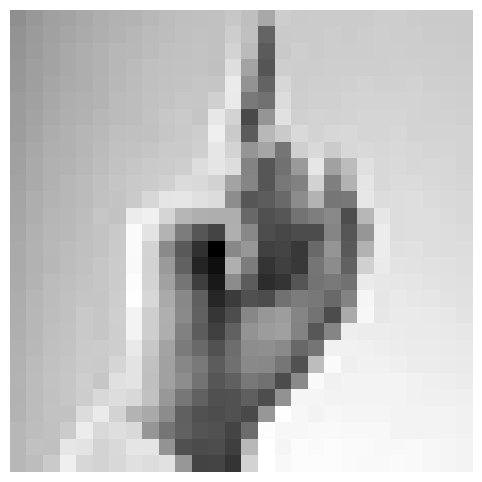

In [20]:
#For this part we based the code from the activity 1a, and we use the rnd_index variable to store in it a random index taken from the training set.
rnd_index = np.random.randint(len(y_train))   # Select a random image for train data set

print(f'La imagen mostrada representa la letra: {alphabet[y_train[rnd_index]]}')

plot_image(x_train[rnd_index])

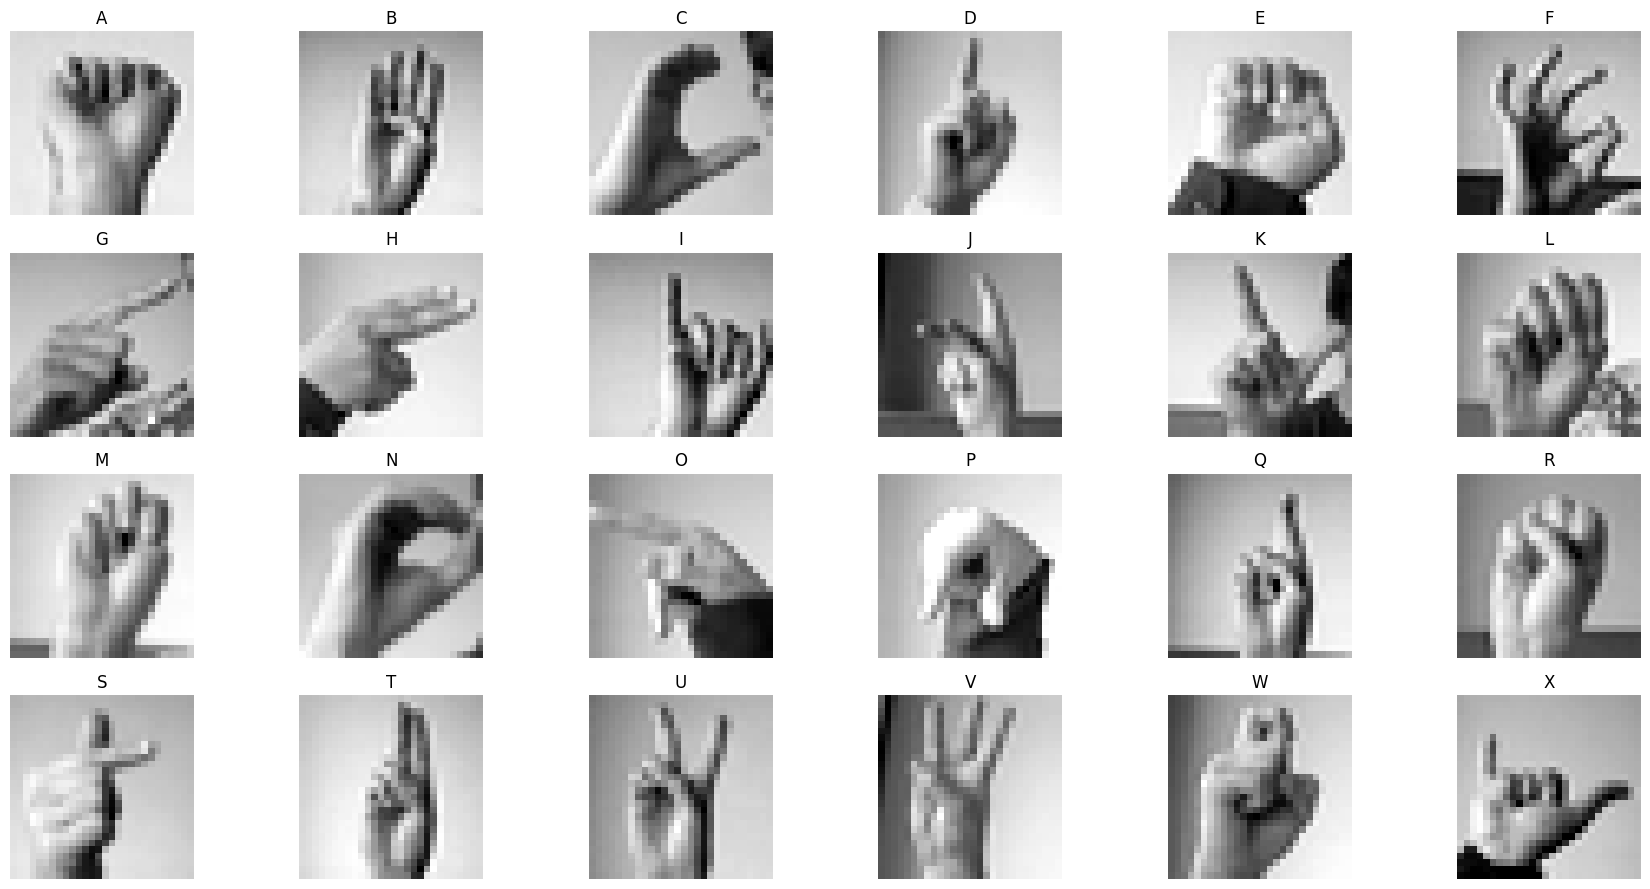

In [21]:
# Visualizar una imagen por letra a partir de las etiquetas originales del CSV.
df_plot = pd.read_csv(os.path.join(DATA_PATH, 'sign_mnist_train.csv'))
df_plot = df_plot.drop_duplicates(subset=['label']).sort_values('label').reset_index(drop=True)
x_plot = df_plot.drop(columns=['label'])

def plot_sample_images():
    plt.figure(figsize=(18, 9))
    for i in range(len(df_plot)):
        plt.subplot(4, 6, i + 1)
        img = x_plot.iloc[i].values.reshape(28, 28)
        original_label = int(df_plot.loc[i, 'label'])
        plt.imshow(img, cmap='gray')
        plt.title(string.ascii_uppercase[original_label])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

plot_sample_images()


----------------------------------------------------

## **Equations for our model**


$$z^1 = W^1 X + b^1$$

$$a^1 = ReLU(z^1) $$

$$z^2 = W^2 a^1 + b^2$$

**Softmax Activacion Function**

$$\hat{y} = \frac{e^{z^{2_k}}}{\sum_j{e^{z_j}}}$$


**Cost Function**:

$$ \mathcal{L}(\hat{y}^{i}, y^{i}) =  - y^{i}  \ln(\hat{y}^{i}) = -\ln(\hat{y}^i)$$


$$ \mathcal{J}(w, b) =  \frac{1}{num\_samples} \sum_{i=1}^{num\_samples}-\ln(\hat{y}^{i})$$


---------------------------------------------------------------------------

# **Additional Functions**

# batch size

#8
#16
#32
#128
#512
#....

_________________________________________________________________________
## **Mini-Batches**

Mini-batches are small, randomly selected subsets of the dataset that are used during training in machine learning.

Mini-batches allow data to be loaded more efficiently into memory, making it possible to work with large datasets without exhausting memory. It is also important to mention that in each iteration, the calculated gradient is not the same due to the differences between mini-batches, helping the model avoid overfitting to the training data.

Instead of using the entire dataset at once (batch gradient descent) or a single sample (stochastic gradient descent), mini-batches strike a balance by processing small, manageable chunks of data in each training step.

Training and evaluating images effectively, both in computer vision and other Machine Learning and Deep Learning tasks, is best achieved through batches. By processing sections of the dataset in each epoch, the evaluation is conducted, leading to a more optimized training process.

__________________________________________________________________________

In [22]:
#Here we defined from the activite 1a, the minibatches function
def create_minibatches(mb_size, x, y, shuffle=True):
  '''
  Create mini-batches from input data.

  x muestras 784
  y muestras 1

  Args:
      mb_size (int): Size of each mini-batch.
      x (numpy.ndarray): Input data (features), where each row represents a sample.
      y (numpy.ndarray): Target data (labels), where each row corresponds to the label of the respective sample in `x`.
      shuffle (bool, optional): If True, shuffle the dataset before splitting into mini-batches. Default is True.

  Returns:
      generator: A generator yielding tuples of (mini_batch_x, mini_batch_y) for each mini-batch.
  '''

  # Ensure that the number of samples in x and y ins the same
  assert x.shape[0] == y.shape[0], 'Las dimensiones de x e y no son compatibles'

  # Total number of samples in the dataset
  total_data = x.shape[0]

  # Suffle the data if requested
  if shuffle:
    indexes = np.arange(total_data)   # Create an array of sample indices
    np.random.shuffle(indexes)        # Randomly suffle the indices
    x = x[indexes]                    # Reorder x based on the suffled indices
    y = y[indexes]                    # Reorder y based on the suffled indices

  # Create and return a generator for mini-batches
  return ((x[i:i+mb_size], y[i:i+mb_size])          # Slices for the current mini-batch
          for i in range(0, total_data, mb_size))   # Iterate in steps of mb_size

## **Our Linear, ReLU and Sequential class**

In [23]:
#Also from the youtube videos and the code from activity 1a, we defined the class np_tensor, which allows us to use it as the existing np.ndarray class, but with the advantage that
#using np_tensor class we can create our own parameters for example to calculate the gradients and use ".grad" later
class np_tensor(np.ndarray): pass

---------------------------------------------------------------

## **Linear class**

The linear class is a basic function used to compute weights and bias for linearly separable problems. It is similar to the perceptron but demonstrates the step-by-step matrix operations within the numpy framework.





## **Kaiming He initalization**

He initialization is a method for initializing the weights in a deep neural network. It is primarily used to address common issues such as gradient vanishing and exploding gradients. This initialization is particularly useful when using ReLU activation functions (or ReLU variants) in neural networks.

Its purpose is to prevent the gradients from becoming too small (vanishing) or too large during the propagation process, keeping the gradients within an appropriate scale, allowing the model to train stably. It is also important to mention that it leads to faster optimization since the weights are better distributed, allowing the model to learn more quickly.

We corrected the code that Dr gave us.

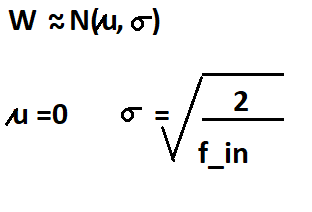



He initialization is effective when the activation function is a ReLU function.

El factor raiz cuadrada de (2/input_size) asegura que los valores iniciales estén dentro de un rango razonable.

---

In [24]:
#Here we created the class linear, using the __init__ we automatically call an instance of a class, we can
#create instances of the class with different dimensions for different layers.
class Linear():

  def __init__(self, input_size, output_size):
    '''
    Initialize parameters using Kaiming He initialization.

    Args:
        input_size (int): Number of input features (size of the input vector).
        output_size (int): Number of output features (size of the output vector).
    '''

    # Kaiming He initialization for weights
    self.W = (np.random.randn(output_size, input_size) * np.sqrt(2/input_size)).view(np_tensor)

    # Bias initialization (Usuarlly zeros)
    self.b = (np.zeros((output_size, 1))).view(np_tensor)

#For the forward function we will use __call__ method, which allows the object to behave like a function, enabling integration
#and automatically passes from the first layer to the next one
  def __call__(self, X):
    '''
    Forward pass for the linear layer.

    Args:
        X (np.ndarray): Input data of shap (batch_size, input_size).

    Returns:
        np.ndarray: Output of the linear transformation, shape (batch_size, output_size).
    '''
    Z = self.W @ X + self.b
    return Z

#We defined a function for the backpropagation method, here we need X which is our input, and Z which is our output, and we want to start getting
#our gradients.
  def backward(self, X, Z):
    '''
    Backward passs for the linear layer.
    Computes gradients with respect to the input, weights, and bias

    Args:
        X (np.ndarray): Input data of shape (batch_size, input_size).
        Z (np.ndarray): Output of the layer from the forward pass.
    '''

    # Gradient of the input (propagated backward)
    X.grad = self.W.T @ Z.grad

    # Gradient of the weights
    self.W.grad = Z.grad @ X.T

    # Gradient of the bias (sum over batch axis)
    self.b.grad = np.sum(Z.grad, axis=1, keepdims=True)

--------------------------------------------------------------------------

## **ReLU class**

ReLU is a simple, efficient, and effective activation function that improves computational efficiency, helps mitigate gradient vanishing, and enables faster learning. This function converts only negative values to zero, while positive values retain their value, introducing non-linearity and allowing the network to learn complex patterns and perform classification tasks.

It is important to mention that neural networks require non-linear functions to learn complex representations of data, as using only linear functions would prevent the neural network from modeling more complex relationships between inputs and outputs.

Implements the ReLU (Rectified Linear Unit) activation function.
    
The ReLU function is defined as:

    ReLU(Z) = max(0, Z)

It is one of the most commonly used activation functions in deep learning, as it helps to introduce non-linearity while being computationally efficient.


----------------------------------------------------------------------

In [25]:
#Here we define the Rectified Linear Unit Class to ensure non-linearity in our model
class ReLU():

  #We defined a forward function, using the method of __call__ to automatically run the forward pass, and we need the parameters self, and Z which is our output.
  def __call__(self, Z):
    '''
    Forward pass of the ReLU activation function.

    Args:
        Z (np.ndarray): Input tensor, typically the output of a linear layer.

    Returns:
        np.ndarray: Output tensor after applying the ReLU activation function.
    '''

    return np.maximum(0, Z)

  #Our backward function, works exactly the same,  to get the gradients of the loss function with respect to Z.
  def backward(self, Z, A):
    '''
    Backward pass of the ReLU activation function.

    Compute the gradient of the loss with respect to the input Z,
    based on the gradient of the output A.

    Args:
        Z (np.ndarray): Input tensor, typically the output of a linear layer.
        A (np.ndarray): Output tensor after applying the ReLU activation function.
    '''

    # Copy the gradient from A (output) to Z (input)
    Z.grad = A.grad.copy()

    # Set gradients to 0 where Z <= 0 (ReLU is inactive for negative inputs)
    Z.grad[Z <= 0] = 0

--------------------------------------------------------------------------

##**Sequential class**

The Sequential class instance enables the integration of functions representing network neurons and their respective activation functions in a sequential manner. This facilitates the generation of various matrix calculations, updates, and predictions necessary for training processes in multilayer neural networks.

--------------------------------------------------------------------------

In [26]:
#Here the sequential_layers class, is created to run the data through the Linear class and the ReLU class:
class Sequential_layers():

  #We create the __init__ to automatically initialize the sequence.
  def __init__(self, layers):
    '''
    Initialize the sequential model.

    Args:
        layers (list): List of layers to be stacked in the sequential model.
    '''

    # Store the layers
    self.layers = layers

    # Placeholder for input data (stores the initial layer)
    self.x = None

    # Directionary to store intermediate outputs for each layer
    self.outputs = {}

#The _call__ function works as the forward method for the layers
  def __call__(self, X):
    '''
    Perform the forward pass through all layers.

    Args:
        X (np.ndarray): Input data of shape (input_size, batch_size).

    Returns:
        np.ndarray: The final output of the network (scores for classification).
    '''

    # Store the initial input
    self.x = X

    # Save the input as the output of "layer 0"
    self.outputs['l0'] = self.x

    # Iterate through all layers and perform forward propagation
    for i, layer in enumerate(self.layers, 1):
      self.x = layer(self.x)    # Pass the output of the previous layer to the next

      self.outputs['l' + str(i)] = self.x   # Store the output for this layer

    return self.x   # Retun the final output

#The backward function helps us to calculate the gradients.
  def backward(self):
    '''
    Perform the backward pass through all layers (in reverse order).

    Uses the stored outputs to calculate gradients for each layer.
    '''

    # Iterate over layers in reverse order
    for i in reversed(range(len(self.layers))):

      # Compute gradients for each layer based on the outputs of the current and next layer
      self.layers[i].backward(self.outputs['l' + str(i)], self.outputs['l' + str(i + 1)])

#Finally the update function we created, will take the result from the backward function and update the values for w and b, based on the learning rate.
  def update(self, learning_rate=1e-3):
    '''
    Update the parameters of all layers using gradient descent.

    Args:
        learning_rate (float, optional): Learning rate for gradient descent. Default is 1e-3.
    '''

    # Iterate through all layers and update their parameters
    for layer in self.layers:

      # Skip activation layers (ReLU does not have parameters to update)
      if isinstance(layer, ReLU): continue

      # Update weights and biases using gradients descent
      layer.W = layer.W - learning_rate * layer.W.grad
      layer.b = layer.b - learning_rate * layer.b.grad

#Here we define the predict function, to make the predictions using the trained model
  def predict(self, X):
    '''
    Make predictions using the trained model.

    Args:
        X (np.ndarray): Input data of shape (input_size, batch_size).

    Returns:
        np.ndarray: Predicted scores for each class.
    '''

    return np.argmax(self.__call__(X), axis=0)


--------------------------------------------------------------------------

## **Cost Function**

The cost function is a measure used to quantify the error of a machine learning model during the training process. Its purpose is to indicate how well or poorly the model is predicting the outcomes compared to the actual values. The higher the value of the cost function, the greater the model's error. The goal of training the neural network is to minimize this loss function by adjusting the network's weights so that the predictions are as close as possible to the actual values. The cost function is fundamental, as it guides the training algorithm to efficiently adjust the neural network's weights over the iterations.

------------------------------------------------------------------------

In [27]:
def softmaxXEntropy(x, y):
    """Entropía cruzada con softmax estable numéricamente y su gradiente."""
    batch_size = x.shape[1]
    shifted = x - np.max(x, axis=0, keepdims=True)  # Evita overflow de exp.
    exp_scores = np.exp(shifted)
    probs = exp_scores / np.sum(exp_scores, axis=0, keepdims=True)
    preds = probs.copy()
    labels = np.asarray(y).reshape(-1).astype(int)
    y_hat = np.clip(probs[labels, np.arange(batch_size)], 1e-12, 1.0)
    cost = -np.mean(np.log(y_hat))
    probs[labels, np.arange(batch_size)] -= 1
    # Se conserva la escala de gradiente del ejemplo original para el learning_rate.
    x.grad = probs.copy()
    return preds, cost


## **Training loop**

In [28]:
def train(model, epochs, mb_size=128, learning_rate=1e-3):
  '''
  Train the model using mini-batch gradient descent.

  Args:
      model (Sequential_layers): The neural network model to be trained.
      epochs (int): Number of training epochs.
      mb_size (int, optional): Size of each mini batch.
      learning_rate (float, optional): Learning rate for parmeter updates.
  '''

  for epoch in range(epochs):
    # Iterate over mini-batches
    for i, (x, y) in enumerate(create_minibatches(mb_size, x_train, y_train)):

      # Forward pass: Compute predictions
      scores = model(x.T.view(np_tensor))   # Transpose x for compatibility

      # Compute loss and its gradient
      _, cost = softmaxXEntropy(scores, y)

      # Backward pass: Compute gradients
      model.backward()

      # Update model parameters
      model.update(learning_rate)

    print(f'Época: {epoch}, costo: {cost}, accuracy: {accuracy(x_val, y_val, mb_size)}')


In [29]:
def accuracy(x, y, mb_size):
  '''
  Compute the accuracy of the model on the given dataset.

  Args:
        x (np.ndarray): Input data of shape.
        y (np.ndarray): True labels of shape.
        mb_size (int): Mini-batch size for evaluation.
        model (Sequential_layers): The trained model.

  Returns:
        float: Accuracy of the model (correct_predictions / total_samples).
  '''
  correct_predictions = 0
  total_samples = 0

  # Iterate over mini-batches
  for i, (x, y) in enumerate(create_minibatches(mb_size, x, y)):

    # Forward pass: Predict probabilities
    preds = model(x.T.view(np_tensor))

    # compare predicted classes with true labels
    correct_predictions += np.sum(np.argmax(preds, axis=0) == y.squeeze())

    # Number of samples in the current batch
    total_samples += preds.shape[1]

  return correct_predictions / total_samples

## **Create your model and train it**

# **Justificación de la arquitectura**

- **Entrada: 784 neuronas.** Cada imagen contiene 28 × 28 píxeles; se usa cada píxel como característica.
- **Primera capa oculta: 256 neuronas.** Permite aprender combinaciones de rasgos de la mano.
- **Segunda capa oculta: 128 neuronas.** Reduce progresivamente la representación antes de clasificar.
- **ReLU:** agrega no linealidad para reconocer patrones complejos; los pesos utilizan inicialización He.
- **Salida: 24 neuronas.** Son las 24 letras representadas en las imágenes (sin J ni Z).
- **Mini-batch: 128.** Equilibrio entre velocidad y frecuencia de actualización.
- **Tasa de aprendizaje: 0.001; épocas: 20.** Valores iniciales razonables para evaluar el desempeño, que se verifican al ejecutar el notebook.

**Comparación con los ejemplos:** uno de los compañeros utilizó 128 y 64 neuronas; el otro probó 256 y 128. Esta versión usa 256 y 128, pero con una salida correcta de 24 clases y etiquetas consecutivas, para evitar errores de dimensión e índices.


In [30]:
# Modelo de 784 entradas, 2 capas ocultas (256 y 128) y 24 salidas.
model = Sequential_layers([
    Linear(784, 256),
    ReLU(),
    Linear(256, 128),
    ReLU(),
    Linear(128, 24)
])

mb_size = 128
learning_rate = 1e-3
epochs = 20
print(f'Arquitectura: 784 -> 256 -> 128 -> 24 | batch={mb_size} | learning_rate={learning_rate} | epochs={epochs}')


Arquitectura: 784 -> 256 -> 128 -> 24 | batch=128 | learning_rate=0.001 | epochs=20


In [31]:
train(model, epochs, mb_size, learning_rate)

Época: 0, costo: 0.046319398817531866, accuracy: 0.7691020635805912
Época: 1, costo: 0.02035671396367746, accuracy: 0.790574456218628
Época: 2, costo: 0.011106515020161146, accuracy: 0.7869492470719465
Época: 3, costo: 0.0067176833147230665, accuracy: 0.7855549358616843
Época: 4, costo: 0.004893495236342345, accuracy: 0.7891801450083659
Época: 5, costo: 0.0035496837205082894, accuracy: 0.7889012827663134
Época: 6, costo: 0.0029621907931436883, accuracy: 0.7900167317345231
Época: 7, costo: 0.001889710944008738, accuracy: 0.7894590072504183
Época: 8, costo: 0.002585839848339626, accuracy: 0.7908533184606804
Época: 9, costo: 0.002185321380258305, accuracy: 0.7922476296709425
Época: 10, costo: 0.0020266741218346197, accuracy: 0.7936419408812047
Época: 11, costo: 0.0013102400632023239, accuracy: 0.7941996653653095
Época: 12, costo: 0.0009017552515121276, accuracy: 0.7930842163970998
Época: 13, costo: 0.0011775313109682762, accuracy: 0.7930842163970998
Época: 14, costo: 0.0009194813525679262

In [32]:
test_accuracy = accuracy(x_test, y_test, mb_size)
print(f'Exactitud en el conjunto de prueba: {test_accuracy:.2%}')


Exactitud en el conjunto de prueba: 78.89%


## **Test your model on Random data from your test set**

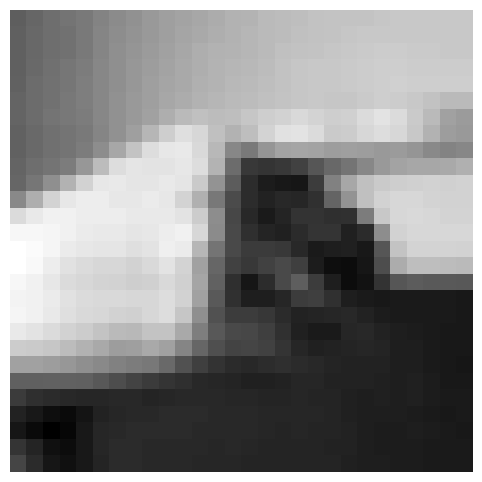

Letra predicha: P | Letra real: G


In [33]:
# Elegir una imagen aleatoria del conjunto de prueba.
idx = np.random.randint(len(y_test))
plot_image(x_test[idx].reshape(28, 28))
pred = model.predict(x_test[idx].reshape(-1, 1).view(np_tensor))
print(f'Letra predicha: {alphabet[int(pred[0])].upper()} | Letra real: {alphabet[int(y_test[idx])].upper()}')


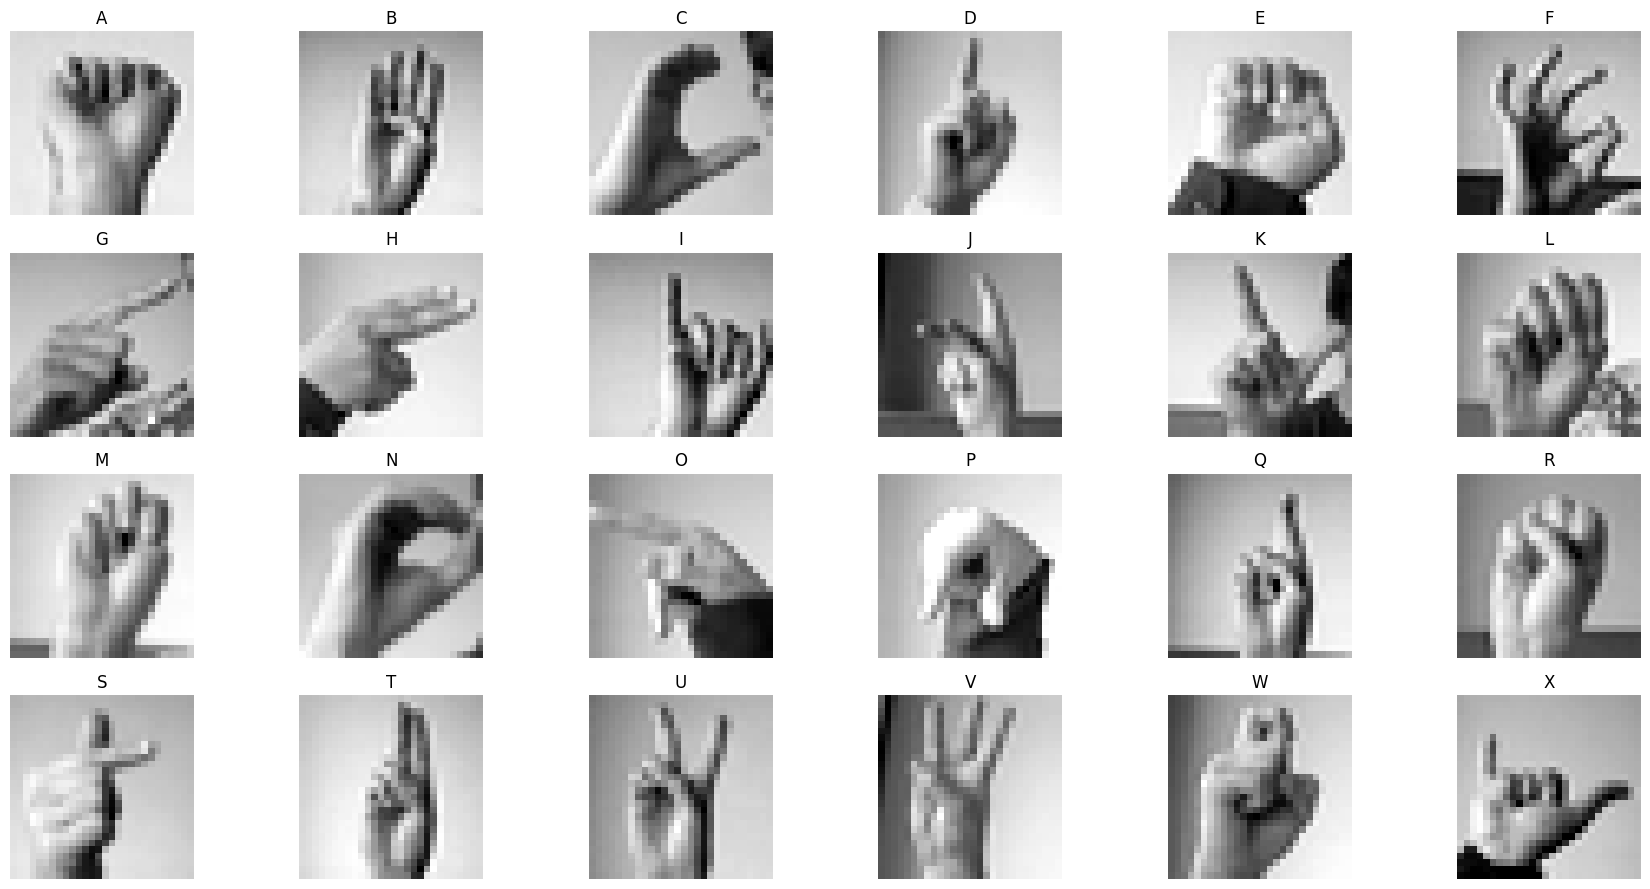

In [34]:
plot_sample_images()

_____________________________________________________
# **Interpretación de los resultados**

Después de entrenar, el notebook imprime el costo de cada época, la exactitud del conjunto de validación y la exactitud del conjunto de prueba. Estos son los resultados que permiten determinar si el modelo aprende las señas y generaliza a imágenes no utilizadas durante el entrenamiento.

- **Costo de entrenamiento:** si disminuye durante las épocas, significa que las predicciones del modelo se van acercando a las clases verdaderas.
- **Exactitud de validación:** permite identificar si los resultados mejoran mientras se entrena; si deja de mejorar, podría haber sobreajuste.
- **Exactitud de prueba:** se calcula con imágenes separadas de la validación y sirve para evaluar el modelo al final.
- **Predicción aleatoria:** la letra estimada se compara con la letra real para observar un ejemplo concreto, pero una sola predicción no representa todo el desempeño.

**Resultado de esta ejecución:** el porcentaje real se mostrará en la celda `Exactitud en el conjunto de prueba` después de entrenar con los CSV. No se fija aquí un porcentaje tomado de los notebooks de los compañeros, ya que sus configuraciones y ejecuciones son distintas.
______________________________________________________________


_____________________________________________________________
# **Conclusiones**

En esta práctica trabajé con una red neuronal profunda totalmente conectada para clasificar imágenes de señas del lenguaje de señas americano. Utilicé los píxeles de cada imagen como entradas y construí el modelo con capas lineales y funciones de activación ReLU, sin depender de una biblioteca que cree automáticamente la red.

Aprendí que las dimensiones de las capas tienen que coincidir: cada salida alimenta la siguiente capa, y el número de salidas finales debe corresponder al número real de clases. También fue importante preparar las etiquetas, porque el archivo original omite la letra J y no todas las etiquetas son consecutivas.

La normalización, los mini-batches, la tasa de aprendizaje y las épocas afectan cómo aprende la red. La exactitud obtenida al ejecutar la práctica permitirá evaluar si la arquitectura elegida funciona bien o si convendría cambiar alguno de esos parámetros. Finalmente, comprendí que no basta con revisar el entrenamiento: hay que evaluar con datos de prueba que el modelo no haya utilizado para ajustar sus pesos.
_____________________________________________________________


------------------------------------------------------
# **Bibliographic References**

[1] [Pepe Cantoral, Ph.D.]. (2021, February 19). Gradient Descent – REDES NEURONALES - (Parte 5) Links to an external site. https://www.youtube.com/watch?v=lnDjwepC-5I.

[2] [Pepe Cantoral, Ph.D.]. (2021, February 22). ¿Por qué usamos el gradiente para entrenar Redes Neuronales? Ejemplo - Deep Learning - (Parte 6) Links to an external site. https://www.youtube.com/watch?v=Cr5cYDrMYZQ

[3] [Pepe Cantoral, Ph.D.]. (2021, March 10). “Backpropagation” – Fundamentos de Deep Learning – (Parte 7)
Links to an external site.https://www.youtube.com/watch?v=4nDsiV3GXa8

[4] [Pepe Cantoral, Ph-D.]. (2021, May 15). ¡Red Neuronal Desde Cero estilo FRAMEWORK de DEEP LEARNING! https://youtu.be/_shpKyA89QQ?si=HphJOAhfI2OcLN4v

[5] [Pepe Cantoral, Ph-D.]. (2021, May 18). ¡Red Neuronal Desde Cero estilo FRAMEWORK de DEEP LEARNING - Parte 2! https://youtu.be/l2v2mVcOx6o?si=ZRkpRhE6qnM1GGVH


[6] [Pepe Cantoral, Ph.D.]. (2021, Jul 6). ¡Red Neuronal usando PyTorch! PyTorch tutorial
Links to an external site.  https://youtu.be/qQELiV1_GHA?si=pmXuHl47zqM5o6GC

[7] Raschka, S., Liu, Y. (., Mirjalili, V., Dzhulgakov, D. (2022). Machine Learning with PyTorch and Scikit-Learn: Develop Machine Learning and Deep Learning Models with Python. United Kingdom: Packt Publishing.

[8] Redes neuronales: Funciones de activación. (s. f.). Google For Developers. https://developers.google.com/machine-learning/crash-course/neural-networks/activation-functions?hl=es-419#:~:text=A%20menudo%2C%20la%20ReLU%20funciona,de%20procesar%20que%20estas%20funciones.

[9] Linear regression: Hyperparameters. (s. f.). Google For Developers. https://developers.google.com/machine-learning/crash-course/linear-regression/hyperparameters#learning_rate

-------------------------------------------------------